# A4 – Efectividad del marketing

El enunciado pide cuatro cosas para A4:

1. La tasa de conversión por tipo de campaña, canal de envío y segmento, para encontrar las combinaciones que dan más retorno.
2. Si el descuento ofrecido en la campaña cambia la conversión, controlando por segmento.
3. El segmento que recibe campañas pero no convierte, con hipótesis sobre las causas basadas en el CRM y las devoluciones.
4. El ROI de cada tipo de campaña: monto de compra convertida contra el costo implícito del descuento ofrecido.

Usamos los datos limpios de A1 (`cargar_limpio`) y el segmento que trae el archivo. Recordatorio de A1.2: la marca `convertido` es lo que registra la empresa, pero solo 179 de las 797 conversiones tienen una compra del cliente en los 30 días siguientes (`conversion_respaldada`). Para tasas usamos la marca; para dinero, solo las compras confirmadas. Las decisiones están en `DECISIONES.md` (A4.1 a A4.5).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from src.carga import cargar_limpio, RAIZ, VENTANA_CONVERSION

d = cargar_limpio()
cli = d["clientes"]
trx = d["transacciones"]
crm = d["interacciones_crm"]
dev = d["devoluciones"]
cam = d["campanas_marketing"].merge(cli[["cliente_id", "segmento", "sin_compras"]], on="cliente_id")
FIG = RAIZ / "figures"

# Colores (paleta de referencia de la guía de visualización)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TEXTO, TEXTO_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def miles(x):
    # 1.234 en vez de 1,234
    return f"{x:,.0f}".replace(",", ".")

print(f"Envíos: {miles(len(cam))} a {miles(cam.cliente_id.nunique())} clientes, del {cam.fecha_envio.min().date()} al {cam.fecha_envio.max().date()}")
print(f"Abiertos: {cam.abierto.mean():.1%} | convertidos: {cam.convertido.mean():.1%} ({cam.convertido.sum()}) | "
      f"con compra confirmada: {cam.conversion_respaldada.sum()}")
print("¿Hay conversiones sin abrir?", ((cam.convertido == 1) & (cam.abierto == 0)).sum())

Envíos: 8.820 a 4.800 clientes, del 2023-01-01 al 2024-12-31
Abiertos: 35.9% | convertidos: 9.0% (797) | con compra confirmada: 179
¿Hay conversiones sin abrir? 0


## 1. Conversión por tipo de campaña, canal y segmento

Para cada grupo mostramos la tasa de apertura, la de conversión (sobre lo enviado), la de conversión entre los que abrieron y el dinero de las compras confirmadas por cada 1.000 envíos, que es el "retorno" que se puede medir.

In [2]:
print("Envíos por tipo de campaña y canal:")
print(pd.crosstab(cam.tipo_campana, cam.canal_campana).to_string())

def conversion(col):
    g = cam.groupby(col).agg(envios=("convertido", "size"), apertura=("abierto", "mean"), conversion=("convertido", "mean"),
                             convertidos=("convertido", "sum"), abiertos=("abierto", "sum"),
                             confirmadas=("conversion_respaldada", "sum"), monto=("monto_respaldado", "sum"))
    lo, hi = proportion_confint(g.convertidos, g.envios, method="wilson")
    t = pd.DataFrame({
        "envíos": g.envios,
        "apertura %": 100 * g.apertura,
        "conversión %": 100 * g.conversion,
        "IC 95%": [f"{100 * a:.1f} – {100 * b:.1f}" for a, b in zip(lo, hi)],
        "conv. si abre %": 100 * g.convertidos / g.abiertos,
        "confirmadas": g.confirmadas,
        "monto por 1.000 envíos": 1000 * g.monto / g.envios,
    })
    p = stats.chi2_contingency(pd.crosstab(cam[col], cam.convertido))[1]
    return t.sort_values("conversión %", ascending=False), p

for col in ["tipo_campana", "canal_campana", "segmento"]:
    t, p = conversion(col)
    print(f"\n{col} (¿la conversión cambia entre grupos? chi-cuadrado p = {p:.4f})")
    print(t.round(1).to_string())

Envíos por tipo de campaña y canal:
canal_campana       email  push_app  redes_sociales   sms
tipo_campana                                             
email_descuento      3099         0               0     0
email_fidelizacion   1748         0               0     0
push_reactivacion       0      1768               0     0
sms_oferta_flash        0         0               0  1345
social_ads              0         0             860     0

tipo_campana (¿la conversión cambia entre grupos? chi-cuadrado p = 0.5753)
                    envíos  apertura %  conversión %      IC 95%  conv. si abre %  confirmadas  monto por 1.000 envíos
tipo_campana                                                                                                          
email_fidelizacion    1748        35.8          10.0  8.6 – 11.4             27.8           43                 11494.4
push_reactivacion     1768        36.1           9.2  7.9 – 10.6             25.4           34                  4597.5
email_

**Tipo y canal son lo mismo.** Cada tipo de campaña sale por un solo canal (por ejemplo, `push_reactivacion` siempre por la app), así que no se puede separar el efecto del tipo del efecto del canal. Los analizamos juntos.

Entre tipos de campaña la conversión va de 8,3% a 10%, y la diferencia no es significativa. **Entre segmentos sí hay diferencias claras:** Premium convierte 13,7% e Inactivo 5,5%. La apertura es parecida en todos (34–37%): la diferencia está en lo que pasa después de abrir.

Ahora las combinaciones tipo × segmento. La pregunta es si alguna combinación funciona mejor de lo que se esperaría sumando el efecto del tipo y el del segmento. Lo comprobamos con una regresión con y sin interacción.

In [3]:
tabla = 100 * cam.pivot_table(index="segmento", columns="tipo_campana", values="convertido", aggfunc="mean")
n = cam.pivot_table(index="segmento", columns="tipo_campana", values="convertido", aggfunc="size")
print("Conversión % por segmento y tipo de campaña:")
print(tabla.round(1).to_string())
print(f"\nEnvíos por celda: de {n.min().min()} a {n.max().max()}")

con = smf.logit("convertido ~ C(tipo_campana) * C(segmento) + descuento_ofrecido", cam).fit(disp=0)
sin = smf.logit("convertido ~ C(tipo_campana) + C(segmento) + descuento_ofrecido", cam).fit(disp=0)
lr = 2 * (con.llf - sin.llf)
print(f"¿Hay combinaciones especiales? Prueba de razón de verosimilitud: p = {stats.chi2.sf(lr, con.df_model - sin.df_model):.2f}")

monto = cam.pivot_table(index="segmento", columns="tipo_campana", values="monto_respaldado", aggfunc="sum")
print("\nMonto de compras confirmadas por cada 1.000 envíos:")
print((1000 * monto / n).round(0).to_string())
print("\nCompras confirmadas por celda:")
print(cam.pivot_table(index="segmento", columns="tipo_campana", values="conversion_respaldada", aggfunc="sum").to_string())

Conversión % por segmento y tipo de campaña:
tipo_campana  email_descuento  email_fidelizacion  push_reactivacion  sms_oferta_flash  social_ads
segmento                                                                                          
Esporádico                9.9                10.2                8.5               9.5         9.1
Frecuente                 8.2                 9.5                8.9               6.2         5.5
Inactivo                  4.7                 5.5                5.5               7.2         5.6
Nuevo                     9.0                11.6               10.9              11.1        13.0
Premium                  12.8                15.7               15.3               9.3        15.7

Envíos por celda: de 83 a 1084
¿Hay combinaciones especiales? Prueba de razón de verosimilitud: p = 0.79

Monto de compras confirmadas por cada 1.000 envíos:
tipo_campana  email_descuento  email_fidelizacion  push_reactivacion  sms_oferta_flash  social_ads
segm

No hay combinaciones especiales (p = 0,79): cada combinación convierte más o menos lo que dan su tipo y su segmento por separado. Las "mejores combinaciones" son las del mejor segmento, sea cual sea el tipo: **Premium**, y después Nuevo y Esporádico.

En dinero confirmado, Premium y Frecuente traen casi todo: compran más y sus compras son más caras. Pero con 179 compras confirmadas repartidas en 25 celdas (varias con 0 o 1), las diferencias de monto entre celdas no son fiables.

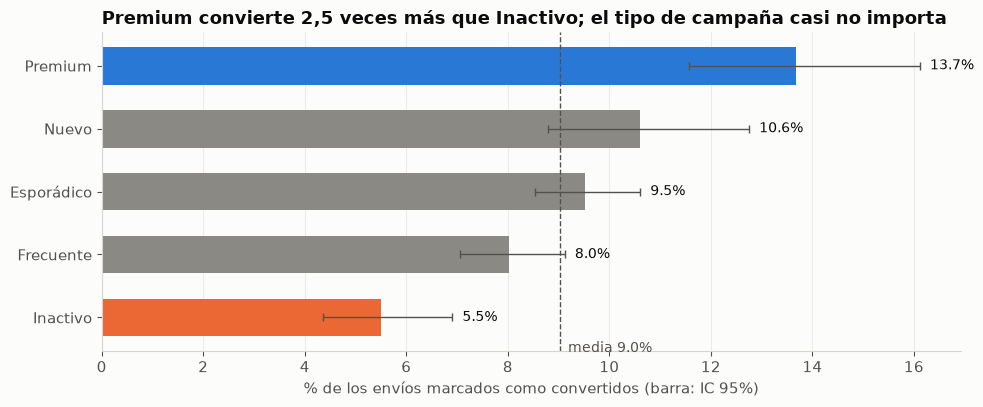

In [4]:
# Gráfico: conversión por segmento con IC 95%
t, _ = conversion("segmento")
t = t.sort_values("conversión %")
g = cam.groupby("segmento").convertido.agg(["sum", "size"]).reindex(t.index)
lo, hi = (100 * np.asarray(x) for x in proportion_confint(g["sum"], g["size"], method="wilson"))
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(10, 4.2))
colores = [NARANJA if s == "Inactivo" else (AZUL if s == "Premium" else GRIS) for s in t.index]
ax.barh(y, t["conversión %"], color=colores, height=0.6)
ax.errorbar(t["conversión %"], y, xerr=[t["conversión %"] - lo, hi - t["conversión %"]], fmt="none", ecolor=TEXTO_2, capsize=3, lw=1)
media = 100 * cam.convertido.mean()
ax.axvline(media, color=TEXTO_2, ls="--", lw=1)
ax.text(media + 0.15, -0.55, f"media {media:.1f}%", color=TEXTO_2, fontsize=10)
for i, (v, h) in enumerate(zip(t["conversión %"], hi)):
    ax.text(h + 0.2, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_yticks(y, t.index)
ax.set_xlabel("% de los envíos marcados como convertidos (barra: IC 95%)")
ax.set_title("Premium convierte 2,5 veces más que Inactivo; el tipo de campaña casi no importa")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a4_conversion_segmento.png", dpi=150)
plt.show()

## 2. ¿El descuento aumenta la conversión?

**Lo primero es ver cómo se repartieron los descuentos (A4.2).** Si la empresa diera más descuento a los clientes que ya iban a comprar, el descuento parecería funcionar aunque no hiciera nada. Comprobamos si el descuento ofrecido depende del segmento, del tipo de campaña o del canal.

In [5]:
print("Envíos por nivel de descuento:", cam.descuento_ofrecido.value_counts().sort_index().to_dict())
for col in ["segmento", "tipo_campana", "canal_campana"]:
    p = stats.chi2_contingency(pd.crosstab(cam[col], cam.descuento_ofrecido))[1]
    print(f"¿El descuento depende de {col}? chi-cuadrado p = {p:.2f}")
print("Descuento medio por segmento:", (100 * cam.groupby("segmento").descuento_ofrecido.mean()).round(1).to_dict())
print("Descuento medio por año:", (100 * cam.groupby(cam.fecha_envio.dt.year).descuento_ofrecido.mean()).round(1).to_dict())

Envíos por nivel de descuento: {0.0: 1481, 0.05: 1504, 0.1: 1456, 0.15: 1467, 0.2: 1454, 0.25: 1458}
¿El descuento depende de segmento? chi-cuadrado p = 0.46
¿El descuento depende de tipo_campana? chi-cuadrado p = 0.19
¿El descuento depende de canal_campana? chi-cuadrado p = 0.20
Descuento medio por segmento: {'Esporádico': 12.5, 'Frecuente': 12.4, 'Inactivo': 12.3, 'Nuevo': 12.3, 'Premium': 12.6}
Descuento medio por año: {2023: 12.6, 2024: 12.3}


El descuento está repartido como si se hubiera sorteado: los seis niveles (0% a 25%) tienen casi los mismos envíos y no dependen del segmento, del tipo, del canal ni del año. Eso es muy útil: **se comporta como un experimento**, y la diferencia de conversión entre niveles de descuento se puede leer como efecto del descuento, no como una simple correlación.

In [6]:
g = cam.groupby("descuento_ofrecido").agg(envios=("convertido", "size"), convertidos=("convertido", "sum"),
                                          apertura=("abierto", "mean"))
lo, hi = proportion_confint(g.convertidos, g.envios, method="wilson")
g["conversión %"] = 100 * g.convertidos / g.envios
g["IC 95%"] = [f"{100 * a:.1f} – {100 * b:.1f}" for a, b in zip(lo, hi)]
g["apertura %"] = 100 * g.apertura
print(g[["envios", "apertura %", "conversión %", "IC 95%"]].round(1).to_string())

m = smf.logit("convertido ~ descuento_ofrecido + C(segmento) + C(tipo_campana)", cam).fit(disp=0)
ef = m.get_margeff().summary_frame().loc["descuento_ofrecido"]
print(f"\nRegresión controlando segmento y tipo: +{ef['dy/dx'] * 10:.1f} puntos de conversión por cada 10 puntos de descuento "
      f"(IC 95%: {ef['Conf. Int. Low'] * 10:.1f} a {ef['Cont. Int. Hi.'] * 10:.1f})")
a = smf.logit("convertido ~ descuento_ofrecido * C(segmento)", cam).fit(disp=0)
b = smf.logit("convertido ~ descuento_ofrecido + C(segmento)", cam).fit(disp=0)
print(f"¿El efecto cambia según el segmento? p = {stats.chi2.sf(2 * (a.llf - b.llf), a.df_model - b.df_model):.2f}")
print("\nConversión % por segmento y descuento:")
print((100 * cam.pivot_table(index="segmento", columns="descuento_ofrecido", values="convertido", aggfunc="mean")).round(1).to_string())

                    envios  apertura %  conversión %      IC 95%
descuento_ofrecido                                              
0.00                  1481        33.9           5.1   4.1 – 6.4
0.05                  1504        35.3           6.9   5.7 – 8.3
0.10                  1456        38.5           8.8  7.4 – 10.4
0.15                  1467        35.8          10.7  9.2 – 12.4
0.20                  1454        37.2          11.4  9.9 – 13.2
0.25                  1458        34.9          11.4  9.9 – 13.1

Regresión controlando segmento y tipo: +2.7 puntos de conversión por cada 10 puntos de descuento (IC 95%: 1.9 a 3.4)
¿El efecto cambia según el segmento? p = 0.18

Conversión % por segmento y descuento:
descuento_ofrecido  0.00  0.05  0.10  0.15  0.20  0.25
segmento                                              
Esporádico           5.9   7.2  10.2  11.7  12.0  10.4
Frecuente            3.7   5.9   8.4  10.0   9.6  11.0
Inactivo             1.5   2.0   6.6   4.8   9.4   8.6
N

Según la marca de conversión, **el descuento funciona**: la conversión pasa de 5,1% sin descuento a 11,4% con 20%, y no sube más con 25%. El efecto se mantiene al controlar segmento y tipo, y es parecido en todos los segmentos. La apertura no cambia, como es lógico: el cliente no sabe el descuento hasta que abre.

### Comprobación con las compras reales

La marca `convertido` la registra la empresa, pero en A1.2 vimos que casi nunca hay una compra detrás. Así que repetimos la pregunta con las **compras reales** del archivo de transacciones: ¿el cliente compra en los 30 días siguientes al envío? Y, para tener una referencia, ¿compraba en los 30 días anteriores? Solo usamos envíos con 30 días de datos a cada lado.

In [7]:
V = VENTANA_CONVERSION
inicio, fin = trx.fecha.min(), trx.fecha.max()
c = cam[((cam.fecha_envio - inicio).dt.days > V) & ((fin - cam.fecha_envio).dt.days >= V)].copy()
p = c[["campana_id", "cliente_id", "fecha_envio"]].merge(trx[["cliente_id", "fecha", "monto_neto"]], on="cliente_id")
dias = (p.fecha - p.fecha_envio).dt.days
c["compra_despues"] = c.campana_id.isin(p[dias.between(0, V)].campana_id)
c["compra_antes"] = c.campana_id.isin(p[dias.between(-V - 1, -1)].campana_id)
c["gasto_despues"] = c.campana_id.map(p[dias.between(0, V)].groupby("campana_id").monto_neto.sum()).fillna(0)
c["gasto_antes"] = c.campana_id.map(p[dias.between(-V - 1, -1)].groupby("campana_id").monto_neto.sum()).fillna(0)

print(f"Envíos con 30 días a cada lado: {miles(len(c))}")
print(f"Compran en los 30 días DESPUÉS del envío: {c.compra_despues.mean():.1%} | en los 30 días ANTES: {c.compra_antes.mean():.1%}")
print(f"  McNemar (¿cambia?): p = {stats.binomtest(int((c.compra_despues & ~c.compra_antes).sum()), int((c.compra_despues != c.compra_antes).sum())).pvalue:.2f}")

print("\n¿Los envíos 'convertidos' tienen más compras reales?")
print((100 * c.groupby("convertido")[["compra_antes", "compra_despues"]].mean()).round(1).to_string())

print("\nCompras reales según el descuento ofrecido:")
r = c.groupby("descuento_ofrecido").agg(conversion_marcada=("convertido", "mean"), compra_despues=("compra_despues", "mean"),
                                        compra_antes=("compra_antes", "mean"), gasto_despues=("gasto_despues", "mean"))
print((r * [100, 100, 100, 1]).round(1).to_string())

mr = smf.logit("compra_despues ~ descuento_ofrecido + compra_antes + C(segmento)",
               c.assign(compra_despues=c.compra_despues.astype(int), compra_antes=c.compra_antes.astype(int))).fit(disp=0)
er = mr.get_margeff().summary_frame().loc["descuento_ofrecido"]
print(f"\nEfecto del descuento sobre la compra REAL: {er['dy/dx'] * 10:+.1f} puntos por cada 10 de descuento "
      f"(IC 95%: {er['Conf. Int. Low'] * 10:.1f} a {er['Cont. Int. Hi.'] * 10:.1f})")
mg = smf.ols("gasto_despues ~ descuento_ofrecido + gasto_antes + C(segmento)", c).fit()
print(f"Efecto sobre el gasto real en 30 días: {mg.params['descuento_ofrecido'] / 10:+.1f} por cada 10 puntos de descuento "
      f"(IC 95%: {mg.conf_int().loc['descuento_ofrecido', 0] / 10:.1f} a {mg.conf_int().loc['descuento_ofrecido', 1] / 10:.1f})")

Envíos con 30 días a cada lado: 8.075
Compran en los 30 días DESPUÉS del envío: 20.8% | en los 30 días ANTES: 21.4%
  McNemar (¿cambia?): p = 0.34

¿Los envíos 'convertidos' tienen más compras reales?
            compra_antes  compra_despues
convertido                              
0                   21.2            20.6
1                   23.1            22.4

Compras reales según el descuento ofrecido:
                    conversion_marcada  compra_despues  compra_antes  gasto_despues
descuento_ofrecido                                                                 
0.00                               5.2            20.9          19.9           85.0
0.05                               6.9            20.7          22.7           94.5
0.10                               9.0            20.8          22.1           81.0
0.15                              10.7            20.0          21.2           88.2
0.20                              11.5            19.7          20.2           73.5
0.

Aquí aparece el hallazgo más importante de A4: **en las compras reales, ni las campañas ni el descuento cambian nada.**

- El 21% de los clientes compra en los 30 días después del envío, y el 21% compraba en los 30 días antes.
- Los envíos marcados como "convertidos" tienen casi las mismas compras reales que los demás (22% contra 21%), tanto después como **antes** del envío. La marca no señala a quien compró por la campaña.
- El descuento, que dobla la conversión marcada, no mueve la compra real ni el gasto real.

Hay dos explicaciones posibles, y los datos no permiten elegir entre ellas: (a) la marca de conversión registra algo que no queda en el archivo de transacciones (por ejemplo, otro sistema o una compra que no se completó), o (b) la marca no es fiable. En cualquiera de los dos casos, **con los datos disponibles no se puede demostrar que las campañas generen ventas**. Lo decimos así en la presentación y lo preguntamos al profesor (A4.3).

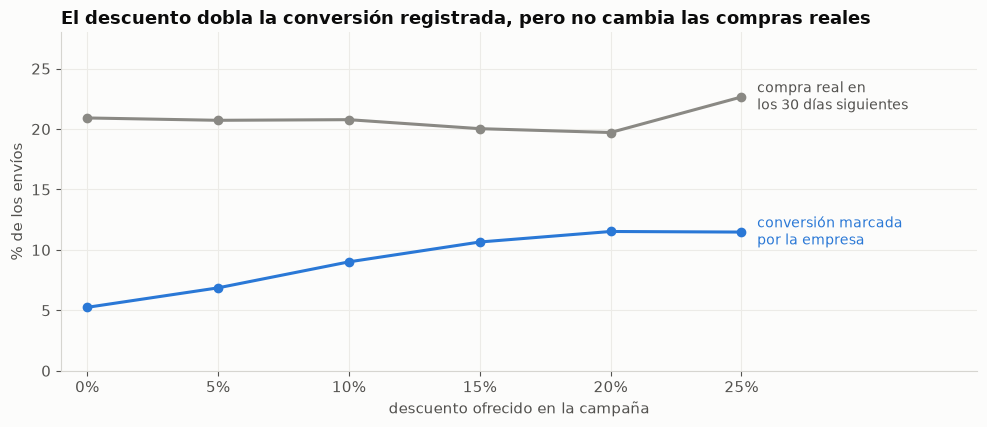

In [8]:
# Gráfico: conversión marcada contra compra real, según el descuento
x = 100 * r.index.to_numpy()
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(x, 100 * r.conversion_marcada, marker="o", color=AZUL, lw=2.2)
ax.plot(x, 100 * r.compra_despues, marker="o", color=GRIS, lw=2.2)
ax.text(x[-1] + 0.6, 100 * r.conversion_marcada.iloc[-1], "conversión marcada\npor la empresa", color=AZUL, va="center", fontsize=10)
ax.text(x[-1] + 0.6, 100 * r.compra_despues.iloc[-1], "compra real en\nlos 30 días siguientes", color=TEXTO_2, va="center", fontsize=10)
ax.set_xticks(x, [f"{v:.0f}%" for v in x])
ax.set_xlim(-1, 34)
ax.set_ylim(0, 28)
ax.set_xlabel("descuento ofrecido en la campaña")
ax.set_ylabel("% de los envíos")
ax.set_title("El descuento dobla la conversión registrada, pero no cambia las compras reales")
fig.tight_layout()
fig.savefig(FIG / "a4_descuento.png", dpi=150)
plt.show()

### La caída de la conversión

El enunciado dice que la conversión cayó de 22% a 11% en 18 meses. En los datos cae a la mitad, pero desde un nivel más bajo: de 11–12% en 2023 a 5–7% en 2024. Miramos si la caída se explica por algo que haya cambiado en los envíos (descuento, segmentos, apertura) y si se ve también en las compras reales.

In [9]:
cam["trimestre"] = cam.fecha_envio.dt.to_period("Q").astype(str)
c["trimestre"] = c.fecha_envio.dt.to_period("Q").astype(str)
t = cam.groupby("trimestre").agg(envios=("convertido", "size"), conversion=("convertido", "mean"), apertura=("abierto", "mean"),
                                 descuento=("descuento_ofrecido", "mean"),
                                 inactivos=("segmento", lambda s: (s == "Inactivo").mean()),
                                 premium=("segmento", lambda s: (s == "Premium").mean()))
t["conv. si abre"] = cam[cam.abierto == 1].groupby("trimestre").convertido.mean()
t["compra real 30 d"] = c.groupby("trimestre").compra_despues.mean()
print((t * [1, 100, 100, 100, 100, 100, 100, 100]).round(1).T.to_string())

cam["anios"] = (cam.fecha_envio - cam.fecha_envio.min()).dt.days / 365
mt = smf.logit("convertido ~ anios + descuento_ofrecido + C(segmento) + C(tipo_campana)", cam).fit(disp=0)
print(f"\nCaída por año, controlando descuento, segmento y tipo: odds × {np.exp(mt.params['anios']):.2f} "
      f"(p = {mt.pvalues['anios']:.1e})")
cr = smf.logit("compra_despues ~ anios + C(segmento)", c.assign(anios=(c.fecha_envio - c.fecha_envio.min()).dt.days / 365,
                                                                compra_despues=c.compra_despues.astype(int))).fit(disp=0)
print(f"Tendencia de la compra real tras el envío: odds × {np.exp(cr.params['anios']):.2f} por año (p = {cr.pvalues['anios']:.2f})")

trimestre         2023Q1  2023Q2  2023Q3  2023Q4  2024Q1  2024Q2  2024Q3  2024Q4
envios            1055.0  1113.0  1094.0  1106.0  1082.0  1128.0  1167.0  1075.0
conversion          11.3    12.3    11.2    10.2     7.9     6.8     7.1     5.6
apertura            37.8    37.1    34.3    33.2    38.5    33.7    36.7    36.3
descuento           12.8    12.6    12.8    12.2    12.4    12.3    12.1    12.3
inactivos           14.3    13.7    13.3    13.9    14.9    13.0    14.6    14.6
premium             11.3    11.2     8.9     9.9    10.4     9.6     8.4    10.0
conv. si abre       29.8    33.2    32.5    30.8    20.6    20.3    19.4    15.4
compra real 30 d    22.3    22.4    20.8    18.5    22.0    20.7    19.9    20.4



Caída por año, controlando descuento, segmento y tipo: odds × 0.63 (p = 5.3e-12)
Tendencia de la compra real tras el envío: odds × 0.97 por año (p = 0.56)


La conversión marcada cae a la mitad, y la caída es un escalón a comienzos de 2024. **No se explica por los envíos:** el descuento medio, la mezcla de segmentos y la apertura son los mismos todo el tiempo. Lo que cae es la conversión entre los que abren (de ~31% a ~19%). Y **las compras reales después de una campaña no caen**: se mantienen en ~20%.

Con estos datos, la "caída de la efectividad del marketing" es una caída en la marca de conversión, sin reflejo en las ventas. Puede ser un cambio en cómo se registra la conversión a partir de 2024; no lo podemos confirmar, y lo anotamos como pregunta para la empresa.

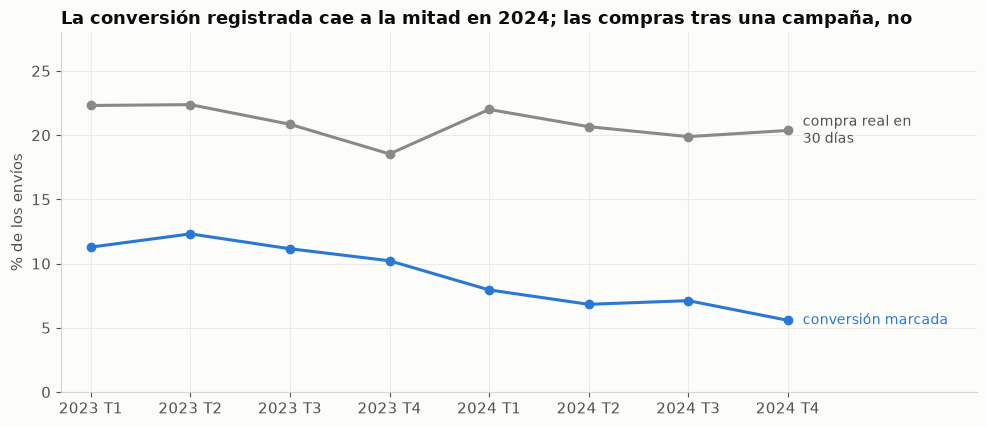

In [10]:
# Gráfico: conversión marcada y compra real por trimestre
x = np.arange(len(t))
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(x, 100 * t.conversion, marker="o", color=AZUL, lw=2.2)
ax.plot(x, 100 * t["compra real 30 d"], marker="o", color=GRIS, lw=2.2)
ax.text(x[-1] + 0.15, 100 * t.conversion.iloc[-1], "conversión marcada", color=AZUL, va="center", fontsize=10)
ax.text(x[-1] + 0.15, 100 * t["compra real 30 d"].iloc[-1], "compra real en\n30 días", color=TEXTO_2, va="center", fontsize=10)
ax.set_xticks(x, [q.replace("Q", " T") for q in t.index])
ax.set_xlim(-0.3, len(t) + 0.9)
ax.set_ylim(0, 28)
ax.set_ylabel("% de los envíos")
ax.set_title("La conversión registrada cae a la mitad en 2024; las compras tras una campaña, no")
fig.tight_layout()
fig.savefig(FIG / "a4_caida_conversion.png", dpi=150)
plt.show()

## 3. El segmento que recibe campañas pero no convierte

En la sección 1 el segmento que menos convierte es **Inactivo** (5,5%, contra 9,0% de media). Recibe tantas campañas como los demás y las abre casi igual; lo que falla es la conversión después de abrir.

**Hipótesis que pide el enunciado (A4.4):** ¿se explica por malas experiencias previas? Probamos, para cada envío, si el cliente había tenido antes una queja, una queja sin resolver o una devolución, controlando el segmento y el descuento. Y miramos qué distingue a los clientes Inactivo.

In [11]:
q = crm[crm.tipo == "queja"][["cliente_id", "fecha", "resolucion"]]
x = cam[["campana_id", "cliente_id", "fecha_envio"]].merge(q, on="cliente_id")
x = x[x.fecha < x.fecha_envio]
y = cam[["campana_id", "cliente_id", "fecha_envio"]].merge(dev[["cliente_id", "fecha_devolucion"]], on="cliente_id")
y = y[y.fecha_devolucion < y.fecha_envio]
z = cam[["campana_id", "cliente_id", "fecha_envio"]].merge(trx[["cliente_id", "fecha"]], on="cliente_id")
z = z[z.fecha < z.fecha_envio]
cam["queja_previa"] = cam.campana_id.isin(x.campana_id).astype(int)
cam["queja_sin_resolver_previa"] = cam.campana_id.isin(x[x.resolucion == "sin_resolver"].campana_id).astype(int)
cam["devolucion_previa"] = cam.campana_id.isin(y.campana_id).astype(int)
cam["compras_previas"] = cam.campana_id.map(z.groupby("campana_id").size()).fillna(0)

print("% de envíos cuyo cliente tuvo antes...")
print((100 * cam.groupby("segmento")[["queja_previa", "queja_sin_resolver_previa", "devolucion_previa"]].mean()).round(1).to_string())

filas = []
for h in ["queja_previa", "queja_sin_resolver_previa", "devolucion_previa"]:
    for ctrl, f in [("segmento y descuento", f"convertido ~ {h} + C(segmento) + descuento_ofrecido"),
                    ("+ compras previas y fecha", f"convertido ~ {h} + C(segmento) + descuento_ofrecido + np.log1p(compras_previas) + anios")]:
        m = smf.logit(f, cam).fit(disp=0)
        lo, hi = np.exp(m.conf_int().loc[h])
        filas.append([h, ctrl, np.exp(m.params[h]), lo, hi, m.pvalues[h]])
print("\nEfecto sobre la conversión (odds ratio: 1 = sin efecto; menor que 1 = convierte menos):")
print(pd.DataFrame(filas, columns=["antecedente", "controlando", "odds ratio", "IC 2,5%", "IC 97,5%", "p"]).round(3).to_string(index=False))

% de envíos cuyo cliente tuvo antes...
            queja_previa  queja_sin_resolver_previa  devolucion_previa
segmento                                                              
Esporádico           9.1                        2.4               15.9
Frecuente            9.6                        2.9               43.3
Inactivo             9.4                        2.7                4.5
Nuevo                8.9                        2.9                7.4
Premium             10.7                        3.5               58.7



Efecto sobre la conversión (odds ratio: 1 = sin efecto; menor que 1 = convierte menos):
              antecedente               controlando  odds ratio  IC 2,5%  IC 97,5%     p
             queja_previa      segmento y descuento       0.870    0.669     1.132 0.300
             queja_previa + compras previas y fecha       1.021    0.781     1.334 0.881
queja_sin_resolver_previa      segmento y descuento       0.710    0.424     1.189 0.193
queja_sin_resolver_previa + compras previas y fecha       0.852    0.508     1.431 0.545
        devolucion_previa      segmento y descuento       0.706    0.583     0.854 0.000
        devolucion_previa + compras previas y fecha       0.854    0.689     1.059 0.151


In [12]:
perfil = cli.groupby("segmento").agg(clientes=("cliente_id", "size"), sin_compras=("sin_compras", "mean"),
                                     compras=("n_compras", "mean"), gasto=("gasto_total", "mean"))
perfil["% sin compras"] = 100 * perfil.pop("sin_compras")
cs = crm.merge(cli[["cliente_id", "segmento"]], on="cliente_id")
perfil["contactos CRM por cliente"] = cs.groupby("segmento").size() / perfil.clientes
perfil["% quejas sin resolver"] = 100 * cs[cs.tipo == "queja"].groupby("segmento").resolucion.apply(lambda s: (s == "sin_resolver").mean())
tv = trx.merge(cli[["cliente_id", "segmento"]], on="cliente_id")
perfil["tasa de devolución %"] = 100 * tv.groupby("segmento").devuelta.mean()
perfil["apertura %"] = 100 * cam.groupby("segmento").abierto.mean()
perfil["conv. si abre %"] = 100 * cam[cam.abierto == 1].groupby("segmento").convertido.mean()
print(perfil.round(1).to_string())
print("\nN.º de compras de los clientes Inactivo:", cli[cli.segmento == "Inactivo"].n_compras.value_counts().sort_index().to_dict())
i = cam[cam.segmento == "Inactivo"]
print("Conversión de Inactivo, sin descuento contra 20–25%:",
      f"{i[i.descuento_ofrecido == 0].convertido.mean():.1%} -> {i[i.descuento_ofrecido >= 0.2].convertido.mean():.1%}")
print("Conversión de Inactivo según si alguna vez compró:", (100 * i.groupby("sin_compras").convertido.mean()).round(1).to_dict())

            clientes  compras   gasto  % sin compras  contactos CRM por cliente  % quejas sin resolver  tasa de devolución %  apertura %  conv. si abre %
segmento                                                                                                                                                 
Esporádico      2827      2.8   955.6            1.5                        0.5                   22.5                  13.7        37.2             25.6
Frecuente       2422     10.5  3619.6            0.0                        0.6                   25.0                  13.5        35.7             22.5
Inactivo        1136      0.8   279.3           22.4                        0.6                   25.2                  12.6        34.7             15.8
Nuevo            810      1.2   403.4           11.6                        0.6                   25.0                  12.1        33.8             31.4
Premium          805     18.5  6559.8            0.0                        

**Las hipótesis del CRM y de las devoluciones no se sostienen:**
- Los clientes Inactivo no tienen más quejas, ni más quejas sin resolver, ni devuelven más que los demás. Al contrario: casi no tienen devoluciones porque casi no compran.
- Haber tenido una queja, una queja sin resolver o una devolución antes del envío no cambia la conversión de forma significativa. La devolución previa parece bajarla, pero el efecto desaparece al tener en cuenta cuántas compras llevaba el cliente y la fecha.

**Lo que sí distingue a los Inactivo:** compraron una sola vez como mucho (el 22% nunca compró). Son clientes con poco vínculo con la tienda. Abren los mensajes, pero casi solo convierten con descuentos grandes: 1,5% sin descuento y alrededor de 9% con 20–25%. Nuestra hipótesis es que son **clientes poco fieles y sensibles al precio**, no clientes molestos. Y, por lo visto en la sección 2, ni siquiera con descuento compran más en la realidad.

## 4. ROI por tipo de campaña

**Cómo lo calculamos (A4.5):**
- **Monto de compra convertida:** el monto de las compras confirmadas (A1.2). Las conversiones marcadas sin compra no tienen monto.
- **Costo implícito del descuento:** el descuento ofrecido × el monto de esa compra. Es lo que la empresa deja de cobrar.
- **ROI sobre ventas** (lo que pide el enunciado): (monto − costo del descuento) / costo del descuento.
- **ROI sobre margen:** igual, pero con el margen bruto de esas compras en vez del monto. Es más realista: la empresa no se queda con todo el monto, solo con su margen.

El ROI sobre ventas depende casi solo del descuento medio: si el descuento es d, sale (1 − d) / d. Por eso lo acompañamos del ROI sobre margen, y de la pregunta de si esas compras habrían ocurrido igual sin la campaña.

In [13]:
pares = cam[cam.conversion_respaldada][["campana_id", "cliente_id", "fecha_envio", "descuento_ofrecido"]].merge(
    trx[["cliente_id", "fecha", "monto_neto", "margen_bruto", "descuento"]], on="cliente_id")
pares = pares[(pares.fecha - pares.fecha_envio).dt.days.between(0, VENTANA_CONVERSION)].sort_values("fecha").drop_duplicates("campana_id")
cam = cam.merge(pares[["campana_id", "margen_bruto"]], on="campana_id", how="left")
cam["costo_descuento"] = cam.descuento_ofrecido * cam.monto_respaldado
print(f"Compras confirmadas: {len(pares)} | ticket medio: {pares.monto_neto.mean():.0f} | "
      f"margen bruto: {pares.margen_bruto.sum() / pares.monto_neto.sum():.1%}")
print(f"¿El descuento de la compra coincide con el de la campaña? correlación = {pares[['descuento_ofrecido', 'descuento']].corr().iloc[0, 1]:.2f}")

def roi(df):
    g = df.agg({"campana_id": "size", "convertido": "sum", "conversion_respaldada": "sum", "monto_respaldado": "sum",
                "margen_bruto": "sum", "costo_descuento": "sum"})
    return pd.Series({"envíos": g.campana_id, "convertidos": g.convertido, "confirmadas": g.conversion_respaldada,
                      "monto": g.monto_respaldado, "margen": g.margen_bruto, "costo descuento": g.costo_descuento,
                      "ROI ventas": (g.monto_respaldado - g.costo_descuento) / g.costo_descuento,
                      "ROI margen": (g.margen_bruto - g.costo_descuento) / g.costo_descuento})

tabla_roi = cam.groupby("tipo_campana").apply(roi)
tabla_roi.loc["Total"] = roi(cam)
print(tabla_roi.round({"monto": 0, "margen": 0, "costo descuento": 0, "ROI ventas": 2, "ROI margen": 2}).to_string())

# Intervalos de confianza del ROI sobre margen (bootstrap de los envíos de cada tipo)
rng = np.random.default_rng(2026)
ic = {}
for tipo, g in cam.groupby("tipo_campana"):
    b = []
    for _ in range(1000):
        s = g.sample(len(g), replace=True, random_state=rng.integers(1e9))
        if s.costo_descuento.sum() > 0:
            b.append((s.margen_bruto.sum() - s.costo_descuento.sum()) / s.costo_descuento.sum())
    ic[tipo] = np.percentile(b, [2.5, 97.5])
print("\nIC 95% del ROI sobre margen:", {k: f"{a:.2f} a {b:.2f}" for k, (a, b) in ic.items()})
print(f"\nMonto confirmado de todas las campañas en 2 años: {miles(cam.monto_respaldado.sum())} "
      f"({cam.monto_respaldado.sum() / trx.monto_neto.sum():.2%} de las ventas)")

Compras confirmadas: 179 | ticket medio: 355 | margen bruto: 23.4%
¿El descuento de la compra coincide con el de la campaña? correlación = 0.04
                    envíos  convertidos  confirmadas    monto   margen  costo descuento  ROI ventas  ROI margen
tipo_campana                                                                                                   
email_descuento     3099.0        274.0         67.0  17455.0   5021.0           2454.0        6.11        1.05
email_fidelizacion  1748.0        174.0         43.0  20092.0   4350.0           3495.0        4.75        0.24
push_reactivacion   1768.0        162.0         34.0   8128.0   1975.0            908.0        7.95        1.17
sms_oferta_flash    1345.0        112.0         22.0  10833.0   2211.0           1237.0        7.76        0.79
social_ads           860.0         75.0         13.0   7149.0   1288.0           1272.0        4.62        0.01
Total               8820.0        797.0        179.0  63657.0  14846.0  


IC 95% del ROI sobre margen: {'email_descuento': '0.64 a 1.65', 'email_fidelizacion': '-0.09 a 0.81', 'push_reactivacion': '0.54 a 2.15', 'sms_oferta_flash': '0.15 a 1.99', 'social_ads': '-0.36 a 1.31'}

Monto confirmado de todas las campañas en 2 años: 63.657 (0.37% de las ventas)


### ROI incremental: ¿las compras habrían ocurrido igual?

El ROI anterior supone que, sin la campaña, esas compras no habrían ocurrido. La sección 2 dice lo contrario: el cliente compra igual con o sin campaña. Hacemos dos cuentas:

- **Según la marca de conversión:** si el descuento causa las conversiones extra que vemos frente al 0% (sección 2), ¿cuánto margen traen esas conversiones extra, frente al descuento que se regala a **todas** las conversiones (incluidas las que habrían ocurrido sin descuento)? Valoramos cada conversión con el ticket medio y el margen de las compras confirmadas.
- **Según las compras reales:** el efecto del descuento es nulo, así que el margen extra es 0 y el ROI incremental es −100% (todo el descuento es costo).

In [14]:
ticket = pares.monto_neto.mean()
margen_pct = pares.margen_bruto.sum() / pares.monto_neto.sum()
base = cam[cam.descuento_ofrecido == 0].convertido.mean()
filas = []
for tipo, g in list(cam.groupby("tipo_campana")) + [("Total", cam)]:
    con_desc = g[g.descuento_ofrecido > 0]
    extra = con_desc.convertido.sum() - base * len(con_desc)          # conversiones que no habría sin descuento
    margen_extra = extra * ticket * margen_pct
    costo = (con_desc.convertido * con_desc.descuento_ofrecido).sum() * ticket   # descuento regalado a todas las conversiones
    filas.append([tipo, len(con_desc), con_desc.convertido.sum(), extra, margen_extra, costo, (margen_extra - costo) / costo])
inc = pd.DataFrame(filas, columns=["tipo", "envíos con descuento", "conversiones", "extra por el descuento",
                                   "margen extra", "costo del descuento", "ROI incremental"]).set_index("tipo")
print(f"Conversión sin descuento (referencia): {base:.1%} | ticket medio {ticket:.0f} | margen {margen_pct:.1%}")
print(inc.round({"extra por el descuento": 0, "margen extra": 0, "costo del descuento": 0, "ROI incremental": 2}).to_string())

# Lo mismo por nivel de descuento: ¿hay algún nivel que se pague solo?
niv = cam.groupby("descuento_ofrecido").convertido.agg(["mean", "size"])
niv["margen extra por envío"] = (niv["mean"] - base) * ticket * margen_pct
niv["costo por envío"] = niv["mean"] * niv.index * ticket
niv["ROI incremental"] = (niv["margen extra por envío"] - niv["costo por envío"]) / niv["costo por envío"]
print("\nPor nivel de descuento (según la marca):")
print(niv.drop(index=0.0).round(2).to_string())

Conversión sin descuento (referencia): 5.1% | ticket medio 355 | margen 23.4%
                    envíos con descuento  conversiones  extra por el descuento  margen extra  costo del descuento  ROI incremental
tipo                                                                                                                              
email_descuento                     2596           253                   120.0        9934.0              14394.0            -0.31
email_fidelizacion                  1445           157                    83.0        6871.0               8952.0            -0.23
push_reactivacion                   1441           142                    68.0        5644.0               8137.0            -0.31
sms_oferta_flash                    1124           101                    43.0        3593.0               6080.0            -0.41
social_ads                           733            68                    30.0        2520.0               3652.0            -0.31
Total

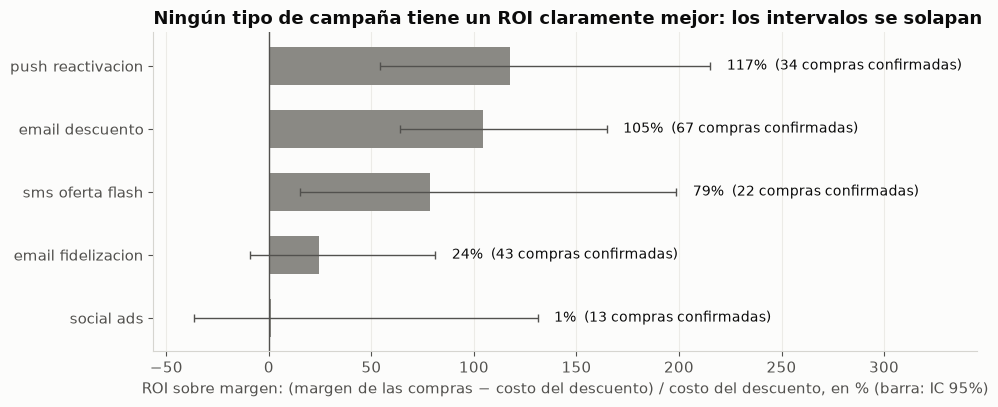

In [15]:
# Gráfico: ROI sobre margen por tipo de campaña, con IC 95%
t = tabla_roi.drop(index="Total").sort_values("ROI margen")
y = np.arange(len(t))
lo = np.array([ic[k][0] for k in t.index]); hi = np.array([ic[k][1] for k in t.index])
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(y, 100 * t["ROI margen"], color=GRIS, height=0.6)
ax.errorbar(100 * t["ROI margen"], y, xerr=[100 * (t["ROI margen"] - lo), 100 * (hi - t["ROI margen"])], fmt="none", ecolor=TEXTO_2, capsize=3, lw=1)
ax.axvline(0, color=TEXTO_2, lw=1)
for i, (k, f) in enumerate(t.iterrows()):
    ax.text(100 * hi[i] + 8, i, f"{100 * f['ROI margen']:.0f}%  ({int(f.confirmadas)} compras confirmadas)", va="center", fontsize=10)
ax.set_yticks(y, [k.replace("_", " ") for k in t.index])
ax.set_xlim(100 * lo.min() - 20, 100 * hi.max() + 130)
ax.set_xlabel("ROI sobre margen: (margen de las compras − costo del descuento) / costo del descuento, en % (barra: IC 95%)")
ax.set_title("Ningún tipo de campaña tiene un ROI claramente mejor: los intervalos se solapan")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a4_roi_tipo.png", dpi=150)
plt.show()

## 5. Resumen de A4

**Conversión por tipo, canal y segmento**
- Se enviaron 8.820 campañas; se abrió el 35,9% y se marcó como convertido el 9,0% (797). Solo 179 conversiones tienen una compra confirmada.
- **El tipo de campaña y el canal casi no importan:** la conversión va de 8,3% a 10,0% y la diferencia no es significativa (p = 0,58). Además, cada tipo sale por un solo canal, así que tipo y canal no se pueden separar.
- **El segmento sí importa:** Premium convierte 13,7%; Inactivo, 5,5%. La apertura es parecida en todos; la diferencia está en lo que pasa después de abrir.
- No hay combinaciones tipo × segmento especiales (p = 0,79). Las mejores combinaciones son las del mejor segmento. En dinero confirmado, Premium y Frecuente traen casi todo.

**Efecto del descuento**
- El descuento se repartió como en un sorteo (no depende del segmento, del tipo, del canal ni del año), así que su efecto se puede medir como en un experimento.
- **Según la marca de conversión, el descuento funciona:** de 5,1% sin descuento a 11,4% con 20%, sin mejora con 25%. Son +2,7 puntos por cada 10 de descuento (IC 95%: 1,9 a 3,4), controlando segmento y tipo, y parecido en todos los segmentos (p = 0,18).
- **Según las compras reales, no:** el 20,8% compra en los 30 días después del envío y el 21,4% compraba en los 30 días antes. El descuento no cambia la compra real (+0,1 puntos por cada 10 de descuento; IC 95%: −0,8 a 1,1) ni el gasto. Los envíos "convertidos" tienen casi las mismas compras reales que los demás (22,4% contra 20,6%), y ya compraban más antes del envío.
- **La caída de la conversión** (de 11,3% a 5,6%) es un escalón a inicios de 2024. No la explican el descuento, la mezcla de segmentos ni la apertura, y las compras reales tras una campaña no caen.
- Conclusión: con estos datos **no se puede demostrar que las campañas generen ventas**. O la marca de conversión registra algo que no está en las transacciones, o no es fiable. Lo presentamos como limitación y como pregunta para la empresa.

**El segmento que no convierte: Inactivo**
- Convierte 5,5% (15,8% de los que abren, contra 22–38% en los demás segmentos).
- **Las hipótesis del CRM y de las devoluciones no se sostienen:** no tienen más quejas ni más quejas sin resolver, y casi no devuelven. Haber tenido una queja, una queja sin resolver o una devolución antes del envío no cambia la conversión cuando se tiene en cuenta cuánto compraba el cliente.
- Lo que los distingue: compraron una vez como mucho (el 22% nunca compró). Solo convierten con descuentos grandes (1,5% sin descuento, 9,0% con 20–25%). Hipótesis: **clientes poco fieles y sensibles al precio**, no clientes molestos.

**ROI por tipo de campaña** (compras confirmadas: 63.657 en 2 años, el 0,37% de las ventas)
- **ROI sobre ventas** (el que pide el enunciado): 5,80 en total, de 4,62 (social ads) a 7,95 (push de reactivación). Depende casi solo del descuento medio.
- **ROI sobre margen:** 0,59 en total. Push de reactivación (1,17) y email de descuento (1,05) salen mejor; social ads (0,01) y email de fidelización (0,24), peor. Pero los intervalos se solapan: con 13 a 67 compras confirmadas por tipo, ningún tipo es claramente mejor.
- **ROI incremental:** aunque aceptemos la marca de conversión, el margen de las conversiones extra no paga el descuento que se regala a todas: −31% en total y negativo en todos los tipos. Solo el descuento de 5% se paga solo (+21%); de 10% en adelante pierde. Según las compras reales, el ROI incremental es −100%.

**Títulos de gráfico candidatos para A5**
- "Premium convierte 2,5 veces más que Inactivo; el tipo de campaña casi no importa" (`figures/a4_conversion_segmento.png`)
- "El descuento dobla la conversión registrada, pero no cambia las compras reales" (`figures/a4_descuento.png`)
- "La conversión registrada cae a la mitad en 2024; las compras tras una campaña, no" (`figures/a4_caida_conversion.png`)
- "Ningún tipo de campaña tiene un ROI claramente mejor: los intervalos se solapan" (`figures/a4_roi_tipo.png`)